# 4 · Görüntü modalitesi (Kriter 5 ve 6)

**Sorular:** Kareler neye benziyor? Sınıflar arasında görsel fark var mı? Ne kadarı eksik ve neden? Kalitesi düşük ya da
aykırı kamera var mı?

**Ön işleme:** Kareler zaten 32×32 gri; yeniden boyutlandırma gerekmiyor. Modele girerken 0–255 → 0–1'e bölünüyor
(`src/dataset.py`).

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


In [2]:
def kareler(h, hub):
    """Bir hub'ın kare dizisi (mmap: yalnız istenen satır diskten okunur) ve 'kare var mı' maskesi."""
    img = np.load(OUT / h / f"{hub}_img.npy", mmap_mode="r")
    meta = pd.read_parquet(OUT / h / f"{hub}_img.parquet")
    return img, meta

## 4.1 Her sınıftan gerçek örnekler

Farklı ev ve hub'lardan, karesi olan rastgele pencereler.

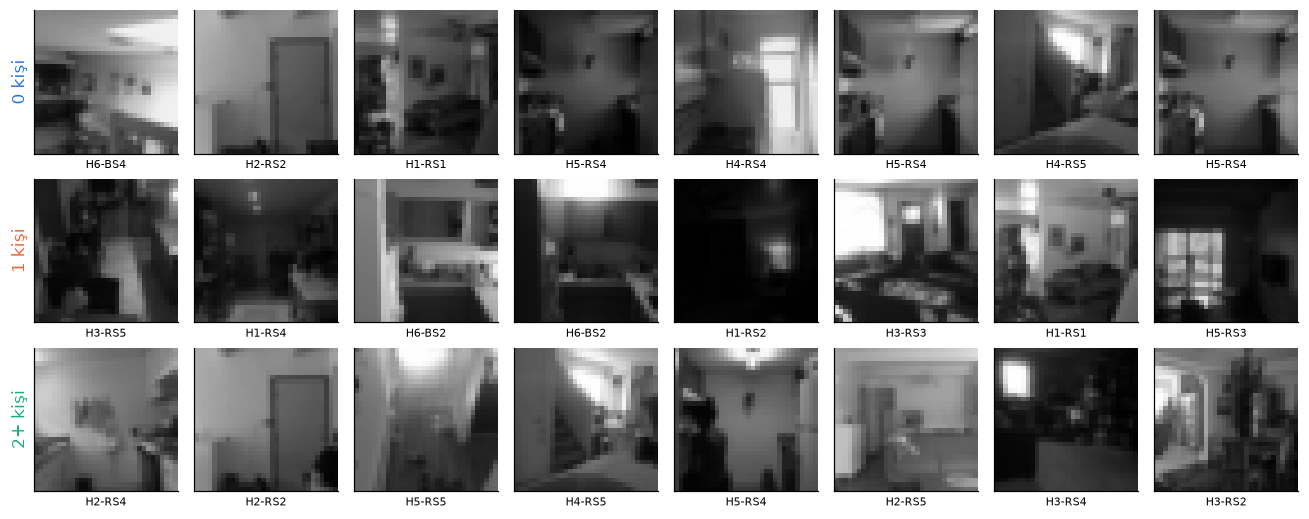

In [3]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(3, 8, figsize=(12, 4.8))
for c in range(3):
    for k in range(8):
        h = rng.choice([x for x in HOMES if (LAB[x]["cls"] == c).any()]); hub = rng.choice(hubs_of(h))
        img, meta = kareler(h, hub)
        cand = np.flatnonzero((LAB[h]["cls"].to_numpy() == c) & (meta["offset"].to_numpy() >= 0))
        i = rng.choice(cand)
        ax[c, k].imshow(img[i], cmap="gray", vmin=0, vmax=255); ax[c, k].set_xticks([]); ax[c, k].set_yticks([])
        ax[c, k].set_xlabel(f"{h}-{hub}", fontsize=7)
    ax[c, 0].set_ylabel(CLS[c], color=RENK[c], fontsize=11)
plt.tight_layout(); plt.show()

**Gözlem:** 32×32'de insan ancak bir leke olarak seçiliyor; sınıfı gözle ayırmak zor. Her hub'ın sahnesi (oda, açı)
çok belirgin. **Modele etkisi:** model odayı ezberleyebilir → ev bazlı bölme şart; görüntü kodlayıcısı küçük ve
düzenlileştirilmiş olmalı.

## 4.2 Kare var mı? Aydınlık / karanlık / hiç yok

Her hub-pencere için: aydınlık kare var (seçildi), yalnız karanlık kare var (yazarlar silmiş), hiç kare yok.

In [4]:
R = []
for h in HOMES:
    for hub in hubs_of(h):
        m = pd.read_parquet(OUT / h / f"{hub}_img.parquet")
        lit = m["offset"] >= 0; dark = (~lit) & (m["n_dark"] > 0)
        R.append({"ev-hub": f"{h}-{hub}", "aydınlık %": 100 * lit.mean(), "yalnız karanlık %": 100 * dark.mean(),
                  "hiç kare yok %": 100 * ((~lit) & ~dark).mean(), "ort. kare/pencere": m["n_frames"].mean()})
R = pd.DataFrame(R).set_index("ev-hub").round(1); R

,aydınlık %,yalnız karanlık %,hiç kare yok %,ort. kare/pencere
ev-hub,,,,
H1-RS1,54.8,44.9,0.2,5.5
H1-RS2,99.4,0.2,0.4,9.8
H1-RS3,55.6,43.9,0.5,5.6
H1-RS4,51.5,48.3,0.2,5.1
H1-RS5,45.8,51.0,3.1,4.6
H2-RS1,69.6,0.0,30.4,7.0
H2-RS2,76.4,0.0,23.6,7.5
H2-RS4,100.0,0.0,0.0,10.0
H2-RS5,76.8,0.0,23.2,7.7


**Okuma:** Çoğu hub'da pencerelerin %31–51'inde yalnız karanlık kare var: gece. H2'de karanlık liste yayınlanmadığı
için bu pencereler "hiç kare yok" sütununda. H1-RS2'de karanlık neredeyse yok: o odada gece de ışık açık.

## 4.3 Parlaklık dağılımı ve sınıf farkı

Karenin ortalama piksel değeri (0 siyah, 255 beyaz). Hız için her hub'dan her 20. aydınlık pencere.

parlaklık                                             kontrast        \
            count  mean   std   min   25%   50%    75%    max    count  mean   
sınıf                                                                          
0 kişi    63890.0  85.1  33.4  10.0  58.3  95.3  112.4  163.1  63890.0  47.2   
1 kişi    74882.0  83.9  32.1   9.9  61.5  91.1  109.4  181.4  74882.0  45.6   
2+ kişi   56312.0  71.7  37.2   9.9  38.8  77.3  103.0  172.7  56312.0  42.7   

                                            
          std  min   25%   50%   75%   max  
sınıf                                       
0 kişi   13.6  5.1  39.2  48.5  56.2  86.1  
1 kişi   14.3  2.9  37.1  46.0  55.5  84.3  
2+ kişi  16.4  5.9  28.1  44.4  54.2  88.9

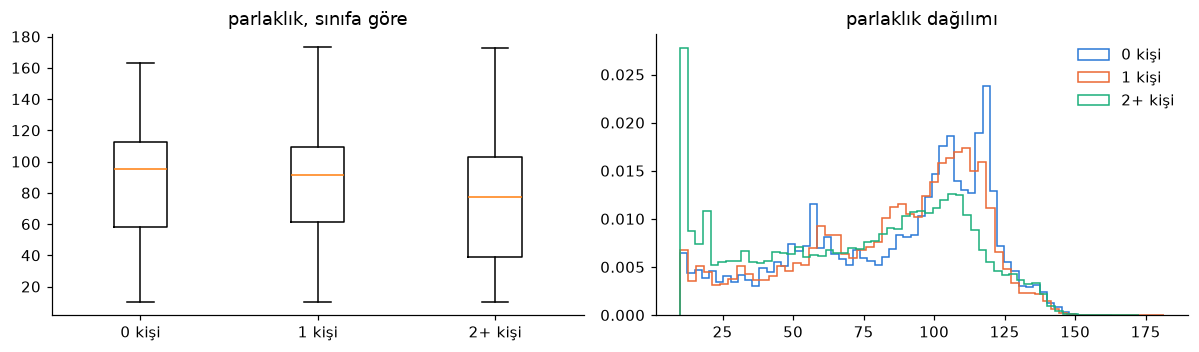

In [5]:
B = []
for h in HOMES:
    for hub in hubs_of(h):
        img, m = kareler(h, hub)
        idx = np.flatnonzero(m["offset"].to_numpy() >= 0)[::20]
        B.append(pd.DataFrame({"parlaklık": img[idx].mean(axis=(1, 2)), "kontrast": img[idx].std(axis=(1, 2)),
                               "sınıf": LAB[h]["cls"].to_numpy()[idx], "gece": LAB[h]["ts"].dt.hour.to_numpy()[idx] < 6}))
B = pd.concat(B)
display(B.groupby("sınıf")[["parlaklık", "kontrast"]].describe().round(1).rename(index=dict(enumerate(CLS))))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].boxplot([B.loc[B["sınıf"] == c, "parlaklık"] for c in range(3)], tick_labels=CLS, showfliers=False)
ax[0].set_title("parlaklık, sınıfa göre")
for c in range(3): ax[1].hist(B.loc[B["sınıf"] == c, "parlaklık"], bins=60, histtype="step", density=True, color=RENK[c], label=CLS[c])
ax[1].set_title("parlaklık dağılımı"); ax[1].legend(frameon=False); plt.tight_layout(); plt.show()

**Gözlem:** Sınıflar arasında parlaklık kutuları büyük ölçüde üst üste. Basit bir istatistik (ortalama parlaklık) sınıfı
ayırmıyor; görüntüden bilgi çıkarmak için karenin kendisine bakan bir model (CNN) gerekiyor.

## 4.4 Ortalama kare: sınıf başına (tek hub)

H1-RS2'nin aydınlık karelerinin sınıf başına ortalaması ve farkı.

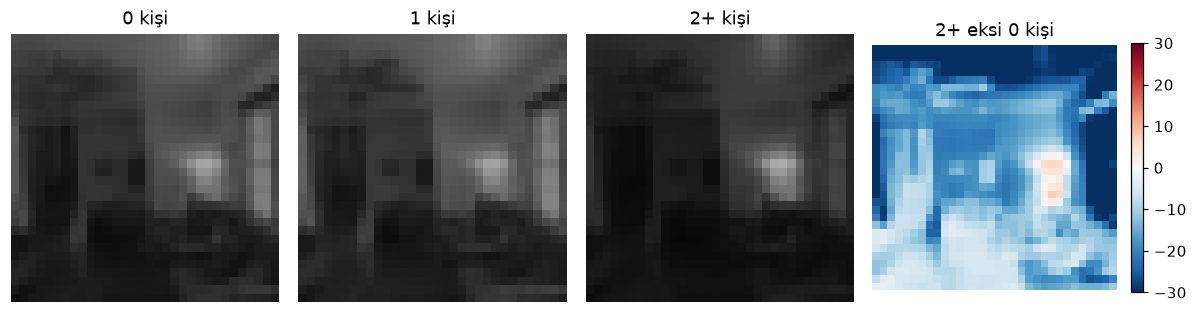

In [6]:
img, m = kareler("H1", "RS2"); y = LAB["H1"]["cls"].to_numpy(); ok = m["offset"].to_numpy() >= 0
ort = [img[np.flatnonzero(ok & (y == c))[::5]].astype("float32").mean(0) for c in range(3)]
fig, ax = plt.subplots(1, 4, figsize=(11, 2.8))
for c in range(3): ax[c].imshow(ort[c], cmap="gray", vmin=0, vmax=255); ax[c].set_title(CLS[c]); ax[c].axis("off")
im = ax[3].imshow(ort[2] - ort[0], cmap="RdBu_r", vmin=-30, vmax=30); ax[3].set_title("2+ eksi 0 kişi"); ax[3].axis("off")
plt.colorbar(im, ax=ax[3], fraction=0.046); plt.tight_layout(); plt.show()

Fark haritasında kırmızı/mavi bölgeler, insanların ve ışığın sık değiştiği yerler (kanepe, kapı, pencere). Bilgi var ama
küçük ve yere bağlı; aynı oda başka evde yok → yine ev bazlı bölme.

## 4.5 Aykırı vaka: H6 BS5 kamerası

Notebook 2'de bu hub'ın kamera–ışık uyumu neredeyse sıfırdı. Saat başına medyanlara bakalım: normal komşu BS4 ile karşılaştırma.

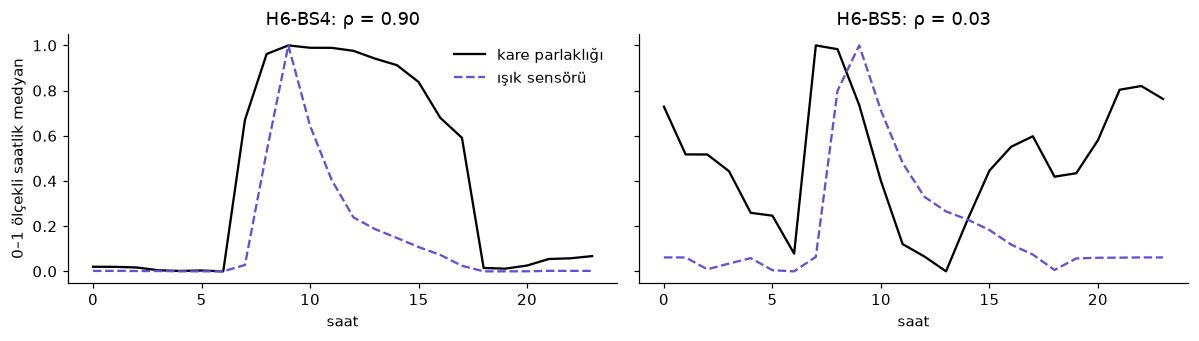

In [7]:
L = ENV_COLS.index("light_lux")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, hub in zip(ax, ["BS4", "BS5"]):
    img, m = kareler("H6", hub); idx = np.flatnonzero(m["offset"].to_numpy() >= 0)[::10]
    df = pd.DataFrame({"saat": LAB["H6"]["ts"].dt.hour.to_numpy()[idx], "parlaklık": img[idx].mean(axis=(1, 2)),
                       "ışık": np.load(OUT / "H6" / f"{hub}_env.npy")[idx, L]})
    s = df.groupby("saat").median(); s = (s - s.min()) / (s.max() - s.min())
    a.plot(s.index, s["parlaklık"], "k-", label="kare parlaklığı"); a.plot(s.index, s["ışık"], "--", color="#6250D6", label="ışık sensörü")
    a.set_title(f"H6-{hub}: ρ = {df['parlaklık'].corr(df['ışık'], method='spearman'):.2f}"); a.set_xlabel("saat")
ax[0].set_ylabel("0–1 ölçekli saatlik medyan"); ax[0].legend(frameon=False); plt.tight_layout(); plt.show()

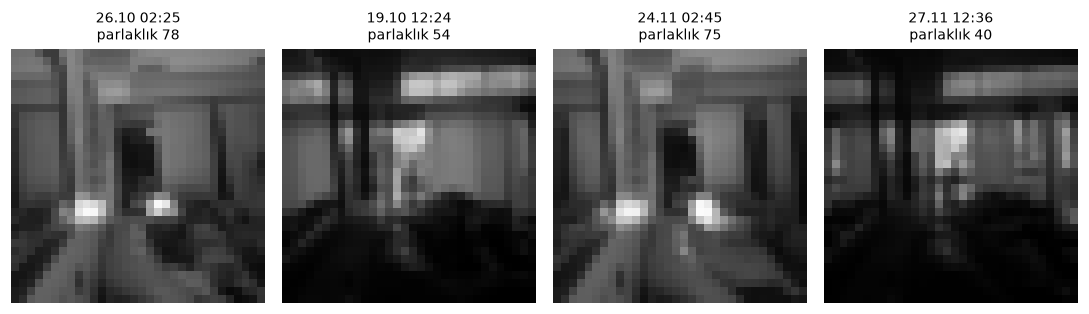

In [8]:
img, m = kareler("H6", "BS5"); ts = LAB["H6"]["ts"]; ok = m["offset"].to_numpy() >= 0
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
def sec(saat, oran):
    c = np.flatnonzero(ok & (ts.dt.hour == saat)); return c[int(len(c) * oran)]
secim = [sec(2, 0.2), sec(12, 0.2), sec(2, 0.8), sec(12, 0.8)]
for a, i in zip(ax, secim):
    a.imshow(img[i], cmap="gray", vmin=0, vmax=255); a.axis("off"); a.set_title(f"{ts[i]:%d.%m %H:%M}\nparlaklık {img[i].mean():.0f}", fontsize=9)
plt.tight_layout(); plt.show()

**Vaka yorumu:** BS4'te parlaklık ışığı izliyor; BS5'te öğlen ışık tepedeyken parlaklık dibe iniyor. Kareler: kamera
pencereye bakıyor, öğlen güçlü ters ışıkta **otomatik pozlama** odayı karartıyor, gece lamba açıkken içeriyi açık gösteriyor.
**Modele etkisi:** "ortalama parlaklık" gibi elle çıkarılmış bir özellik bu hub'da yanıltıcı → modele ham kare verilecek;
bu hub hata analizinde ayrıca izlenecek.